# Parte 2 — Clasificación de fenómenos meteorológicos

**Equipo 06:** Felipe Cadavid Rincón, Katherine Rodriguez Mejia y Luis Carlos Vanegas Zapata.

## Cómo estudiar este notebook
Ejecuta las celdas en orden. Antes de ejecutar código, lee su objetivo; después,
interpreta la salida y responde las preguntas de estudio. Las secciones pendientes
no contienen resultados ni implementaciones supuestas.

## 1. Problema, decisiones y alcance
Fuente: [Weather Image Recognition en Kaggle](https://www.kaggle.com/datasets/jehanbhathena/weather-dataset).
El dataset fue propuesto por el equipo y aceptado por el docente.

- **Unidad de clasificación:** una fotografía, con etiqueta tomada de su carpeta.
- **Condición del tutorial confirmada por el equipo:** Gabor es principal; HOG es opcional y decidimos incluirlo.
- **Gabor:** reutilizaremos el banco de la Parte 1: 4 orientaciones × 3 longitudes de onda, con media y desviación de respuesta al cuadrado (24 valores por ROI).
- **Forma y ROI:** estudiaremos regiones segmentadas y agregaremos sus descriptores por fotografía. Su utilidad aún debe comprobarse; no llamaremos objetos meteorológicos a máscaras arbitrarias.
- **Datos:** verificaremos si existen las 11 clases esperadas y al menos 60 imágenes válidas por clase. Una carpeta es una etiqueta operacional, no una prueba de corrección semántica.
- **Particiones futuras:** 70/15/15, controlando duplicados. Una partición de Kaggle no demuestra fotos tomadas otro día o cámara.
- **Aplicación e interfaz:** se desarrollarán al final. La adaptación de la detección múltiple original a clasificación meteorológica global debe quedar explícita.

**Ruta de trabajo:** auditoría → particiones → preprocesamiento/ROI → características → entrenamiento → evaluación → exportación → interfaz.

**Pregunta:** ¿por qué diez ROI de una foto no son diez fotografías independientes?

## 2. Entorno y configuración
**Objetivo:** usar rutas conocidas y una semilla fija, sin instalar paquetes silenciosamente.

Instala las dependencias una sola vez en el mismo entorno del notebook. En Jupyter/Colab,
puedes ejecutar `%pip install -r requirements.txt` (con el repositorio disponible).
Para un Colab sin ese archivo: `%pip install kagglehub numpy pandas Pillow matplotlib`.
Si se solicita reiniciar el kernel, hazlo antes de continuar.

Las funciones viven en `src/dataset.py`: puedes abrirlo para leer su implementación.
El notebook debe ejecutarse desde la raíz del repositorio; en Colab también necesitas `src/`.

In [14]:
import sys
print(sys.executable)

c:\Users\cadav\Documents\GitHub\weather-detector-app\.venv\Scripts\python.exe


In [15]:
from pathlib import Path
import json
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

from src.dataset import IMAGE_EXTENSIONS, find_class_root, audit_dataset

# Rutas relativas al proyecto: no dependen del nombre de usuario del computador.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "dataset.py").is_file():
    raise RuntimeError("Ejecuta desde la raíz del proyecto, con la carpeta src disponible.")
MANIFEST_DIR = PROJECT_ROOT / "data" / "manifests"
REPORT_DIR = PROJECT_ROOT / "reports" / "audit"
for directory in (MANIFEST_DIR, REPORT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

SEED = 42
DATASET_HANDLE = "jehanbhathena/weather-dataset"
EXPECTED_CLASSES = 11  # Expectativa por verificar, no resultado observado.
MIN_IMAGES_PER_CLASS = 60
LOCAL_DATASET_PATH = None  # Alternativa: Path(r"ruta/a/dataset_descargado")

# Registrar versiones ayuda a reproducir y diagnosticar cambios de entorno.
environment = {name: version(name) for name in ("numpy", "pandas", "Pillow", "matplotlib")}
environment["python"] = platform.python_version()
print("Proyecto:", PROJECT_ROOT)
display(pd.Series(environment, name="versión"))

Proyecto: C:\Users\cadav\Documents\GitHub\weather-detector-app


numpy          2.5.4
pandas         2.3.3
Pillow        12.3.0
matplotlib    3.11.2
python        3.13.7
Name: versión, dtype: object

## 3. Descarga o selección de datos locales
**Objetivo:** localizar la fuente sin copiar ni modificar imágenes.

KaggleHub descarga en su caché y devuelve su ruta. Si ya tienes una copia, configura
`LOCAL_DATASET_PATH` arriba. Una carpeta envolvente puede contener otra carpeta con
las clases: la función busca una raíz única. Si hay ambigüedad, detente y define
`CLASS_ROOT` manualmente tras revisar las carpetas.

Los errores de red o autenticación deben resolverse antes de continuar; no se
sustituirán por imágenes inventadas. No escribas credenciales en el notebook.

In [16]:
if LOCAL_DATASET_PATH is None:
    import kagglehub
    # Esta es la única celda de esta etapa que necesita acceso a Internet.
    download_path = Path(kagglehub.dataset_download(DATASET_HANDLE))
    environment["kagglehub"] = version("kagglehub")
else:
    download_path = Path(LOCAL_DATASET_PATH).expanduser().resolve()

CLASS_ROOT = find_class_root(download_path)
print("Raíz de clases:", CLASS_ROOT)
print("Directorios:", sorted(p.name for p in CLASS_ROOT.iterdir() if p.is_dir()))

Raíz de clases: C:\Users\cadav\.cache\kagglehub\datasets\jehanbhathena\weather-dataset\versions\3\dataset
Directorios: ['dew', 'fogsmog', 'frost', 'glaze', 'hail', 'lightning', 'rain', 'rainbow', 'rime', 'sandstorm', 'snow']


## 4. Auditoría: clases, integridad y dimensiones
**Objetivo:** construir un manifiesto, una fila por archivo, antes del entrenamiento.

`audit_dataset` verifica que cada imagen pueda abrirse y decodificarse. Registra
dimensiones después de respetar orientación EXIF y dos huellas SHA-256: archivo
y píxeles RGB. Un archivo dañado queda registrado con su error; no se borra.
Las imágenes con extensiones no reconocidas no entran al manifiesto.

**Interpretación:** observa el conteo de imágenes válidas por clase, el desequilibrio
y el rango de dimensiones. La etiqueta se obtiene del primer directorio bajo
`CLASS_ROOT`, incluso si hay subcarpetas dentro de cada clase.

**Cómo leer la tabla de tamaños:** `width` es ancho y `height` es alto, en píxeles.
`count` cuenta imágenes; `mean` es el promedio; `std` indica dispersión; `min` y
`max` son extremos; 25 %, 50 % y 75 % son percentiles. El 50 % es la mediana.
En la auditoría hay 6862 imágenes medidas: la mediana del ancho es 400 px y la del
alto es 280 px. Los tamaños varían, por eso normalizaremos antes de extraer rasgos.
Cada columna se resume por separado: el máximo ancho y el máximo alto podrían
pertenecer a fotografías distintas. Que una imagen sea válida significa que se
puede leer, no que su etiqueta sea correcta o que no esté repetida.

,archivos,validas,invalidas,cumple_minimo
label,,,,
dew,698,698,0,True
fogsmog,851,851,0,True
frost,475,475,0,True
glaze,639,639,0,True
hail,591,591,0,True
lightning,377,377,0,True
rain,526,526,0,True
rainbow,232,232,0,True
rime,1160,1160,0,True


Clases encontradas: 11; esperadas: 11


,width,height
count,6862.000000,6862.000000
mean,520.029729,373.841737
std,352.023100,251.419153
min,117.000000,91.000000
25%,400.000000,255.000000
50%,400.000000,280.000000
75%,500.000000,400.000000
max,4863.000000,3174.000000


,relative_path,error


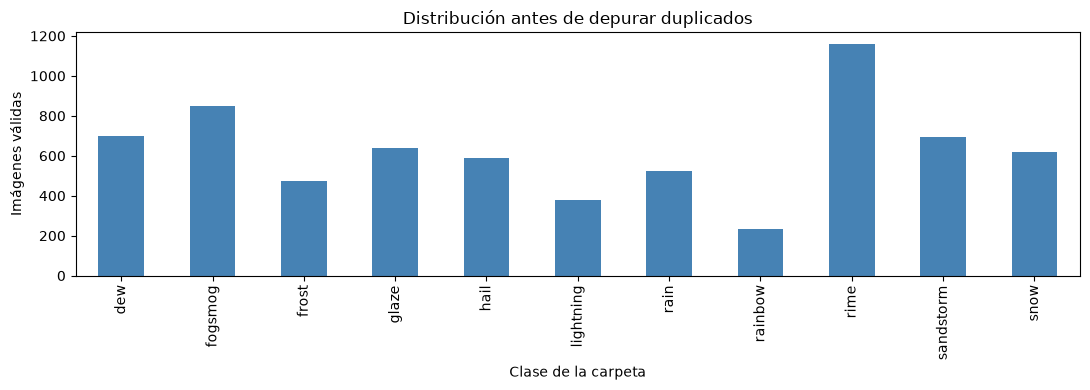

In [17]:
manifest = audit_dataset(CLASS_ROOT)
valid_images = manifest.loc[manifest["valid"]].copy()
invalid_images = manifest.loc[~manifest["valid"]].copy()

# Incluir incluso directorios sin imágenes para no ocultar clases vacías.
class_names = sorted(p.name for p in CLASS_ROOT.iterdir()
                     if p.is_dir() and not p.name.startswith("."))
summary = (manifest.groupby("label").agg(
    archivos=("image_id", "size"), validas=("valid", "sum")
).reindex(class_names, fill_value=0))
summary["invalidas"] = summary["archivos"] - summary["validas"]
summary["cumple_minimo"] = summary["validas"] >= MIN_IMAGES_PER_CLASS
display(summary)
print(f"Clases encontradas: {len(class_names)}; esperadas: {EXPECTED_CLASSES}")
if len(class_names) != EXPECTED_CLASSES:
    print("REVISAR: la estructura no coincide con las once clases esperadas.")
if not summary["cumple_minimo"].all():
    print("REVISAR: existen directorios con menos de 60 imágenes válidas.")
if valid_images.empty:
    raise RuntimeError("No hay imágenes válidas para continuar.")
display(valid_images[["width", "height"]].describe())
display(invalid_images[["relative_path", "error"]])

ax = summary["validas"].plot.bar(figsize=(11, 4), color="steelblue")
ax.set(xlabel="Clase de la carpeta", ylabel="Imágenes válidas", title="Distribución antes de depurar duplicados")
plt.tight_layout()
plt.savefig(REPORT_DIR / "class_counts.png", dpi=150)
plt.show()

### 4.1. Duplicados y prevención de fuga de información
**Objetivo:** identificar imágenes idénticas antes de dividir los datos.

La huella del archivo detecta copias byte por byte. La de píxeles también detecta
archivos diferentes que decodifican a la misma imagen RGB orientada. No detecta
automáticamente recortes, versiones comprimidas ni fotos casi iguales.

La regla acordada se implementa en la sección 5: conservar una copia por grupo
con la misma etiqueta y excluir todas las copias de grupos con etiquetas distintas.
No se borran fotografías: solo se registra cuáles entran al experimento.
Elegimos la primera ruta en orden alfabético para que la selección sea reproducible.

In [18]:
duplicate_files = valid_images.loc[
    valid_images.duplicated("file_sha256", keep=False)
].sort_values("file_sha256")
duplicate_pixels = valid_images.loc[
    valid_images.duplicated("pixel_sha256", keep=False)
].sort_values("pixel_sha256")

label_counts = valid_images.groupby("pixel_sha256")["label"].nunique()
conflicting_hashes = label_counts.index[label_counts > 1]
conflicting_labels = valid_images.loc[
    valid_images["pixel_sha256"].isin(conflicting_hashes)
]

print("Archivos involucrados en duplicación exacta:", len(duplicate_files))
print("Imágenes involucradas en duplicación de píxeles:", len(duplicate_pixels))
print("Grupos con etiquetas diferentes:", len(conflicting_hashes))
display(duplicate_pixels[["relative_path", "label", "pixel_sha256"]])
display(conflicting_labels[["relative_path", "label", "pixel_sha256"]])

Archivos involucrados en duplicación exacta: 368
Imágenes involucradas en duplicación de píxeles: 372
Grupos con etiquetas diferentes: 1


,relative_path,label,pixel_sha256
207,dew/2415.jpg,dew,004dae6d1c0095a9777dff0bff0abb51edd58629d51501...
566,dew/2774.jpg,dew,004dae6d1c0095a9777dff0bff0abb51edd58629d51501...
2865,hail/0202.jpg,hail,0201f6fa2f987f99814f1ed0c0bbd67316af1e94aa57ef...
2851,hail/0188.jpg,hail,0201f6fa2f987f99814f1ed0c0bbd67316af1e94aa57ef...
2870,hail/0207.jpg,hail,0201f6fa2f987f99814f1ed0c0bbd67316af1e94aa57ef...
...,...,...,...
4863,rime/5404.jpg,rime,f9a0ccfbb28d3a362e6ad8a29d56e3af68f56c4ca4d7cb...
2940,hail/0277.jpg,hail,fadd0b37f80ccd78018fa7022a64a58dd09c3bd556e43c...
3038,hail/0375.jpg,hail,fadd0b37f80ccd78018fa7022a64a58dd09c3bd556e43c...
1586,frost/3637.jpg,frost,ffbe81dfbb01eabf13618c122f7382bd306f94a319cd54...


,relative_path,label,pixel_sha256
1417,fogsmog/4794.jpg,fogsmog,429bc2400d37aa58357105158b20cb4c21992f968bba6f...
6132,sandstorm/3491.jpg,sandstorm,429bc2400d37aa58357105158b20cb4c21992f968bba6f...


### 4.2. Galería reproducible por clase
**Objetivo:** inspeccionar etiquetas y variabilidad visual. Las muestras se eligen
con semilla fija; no se buscan ejemplos que favorezcan una técnica.

Esta inspección exploratoria precede a la partición. Tras separar prueba, no
usaremos sus imágenes para diseñar segmentación ni ajustar hiperparámetros.

**Preguntas:** ¿hay escenas completas y detalles cercanos? ¿La forma de un objeto
es visible en todas las clases? ¿Qué pares de etiquetas parecen ambiguos?

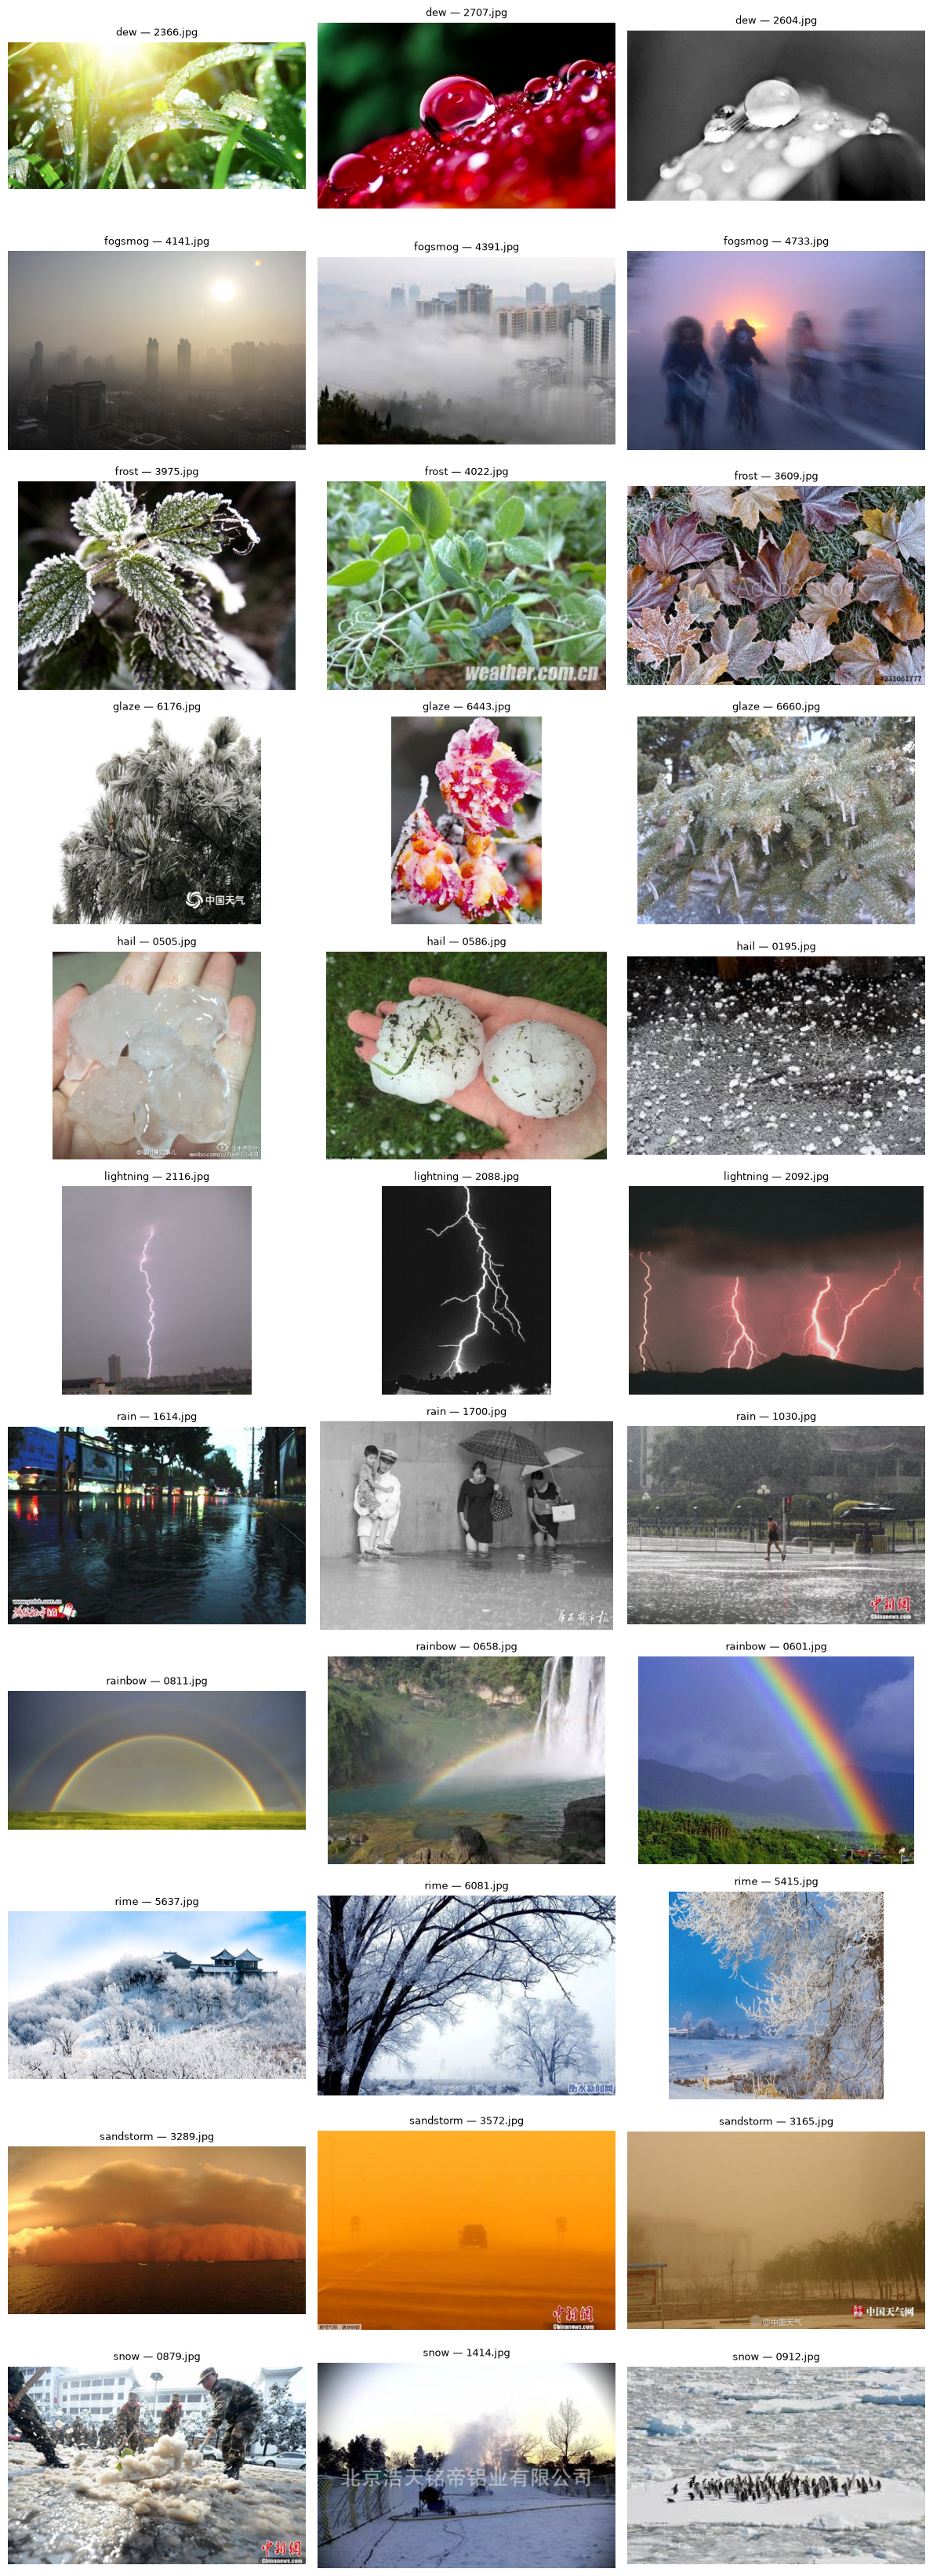

In [19]:
SAMPLES_PER_CLASS = 3
gallery_classes = sorted(valid_images["label"].unique())
fig, axes = plt.subplots(len(gallery_classes), SAMPLES_PER_CLASS,
                         figsize=(12, 3 * len(gallery_classes)), squeeze=False)
for row, label in enumerate(gallery_classes):
    subset = valid_images.loc[valid_images["label"] == label]
    samples = subset.sample(n=min(SAMPLES_PER_CLASS, len(subset)), random_state=SEED)
    for column, (_, sample) in enumerate(samples.iterrows()):
        with Image.open(CLASS_ROOT / sample["relative_path"]) as image:
            preview = ImageOps.exif_transpose(image).convert("RGB")
            preview.thumbnail((640, 640))  # Solo visualización: no altera el archivo.
            axes[row, column].imshow(preview)
        axes[row, column].set_title(f"{label} — {Path(sample['relative_path']).name}", fontsize=9)
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.savefig(REPORT_DIR / "class_examples.png", dpi=120)
plt.show()

### 4.3. Guardar evidencia de auditoría
**Objetivo:** persistir registros y parámetros sin afirmar que ya hay particiones.
Los identificadores se calculan a partir de rutas relativas. Las huellas de contenido
permiten detectar cambios en archivos. Guarda también la versión de la fuente si
Kaggle la cambia. La ubicación absoluta registrada es local; al mover el proyecto,
selecciona nuevamente la raíz del dataset.

In [20]:
manifest.to_csv(MANIFEST_DIR / "audit.csv", index=False)
summary.to_csv(REPORT_DIR / "class_summary.csv", index_label="label")
invalid_images.to_csv(REPORT_DIR / "invalid_images.csv", index=False)
duplicate_pixels.to_csv(REPORT_DIR / "duplicate_pixels.csv", index=False)
conflicting_labels.to_csv(REPORT_DIR / "conflicting_labels.csv", index=False)
audit_config = {
    "dataset_handle": DATASET_HANDLE, "class_root": str(CLASS_ROOT),
    "seed": SEED, "expected_classes": EXPECTED_CLASSES,
    "observed_classes": class_names, "versions": environment,
    "recognized_extensions": sorted(IMAGE_EXTENSIONS),
    "split_created": False,
}
(MANIFEST_DIR / "audit_config.json").write_text(
    json.dumps(audit_config, ensure_ascii=False, indent=2), encoding="utf-8")
print("Auditoría guardada en:", MANIFEST_DIR)
print("Tablas y figuras en:", REPORT_DIR)

Auditoría guardada en: C:\Users\cadav\Documents\GitHub\weather-detector-app\data\manifests
Tablas y figuras en: C:\Users\cadav\Documents\GitHub\weather-detector-app\reports\audit


### Hallazgos de la auditoría y apuntes de estudio

Los registros guardados en `data/manifests/audit.csv` confirman:

| Hallazgo | Resultado y significado |
|---|---|
| Archivos examinados | 6862; todos se pudieron leer |
| Clases | 11 carpetas usadas como etiquetas |
| Duplicación de archivos | 368 archivos participan en grupos idénticos byte por byte |
| Duplicación de píxeles | 372 imágenes participan en grupos con igual contenido RGB orientado |
| Conflictos de etiqueta | Un grupo: `fogsmog/4794.jpg` y `sandstorm/3491.jpg` son la misma imagen |
| Galería | El equipo observó clases diferenciables en los ejemplos revisados |

**372 imágenes involucradas no significa eliminar 372 imágenes.** Si un grupo
tiene tres copias con la misma etiqueta, conservamos una y excluimos dos.
La depuración acordada excluye 189 copias repetidas y las dos imágenes del grupo
con etiquetas contradictorias. Quedan **6671 imágenes únicas**. Ningún archivo
original se borra. Estos números corresponden a esta ejecución del dataset;
las celdas los recalculan si cambia la fuente.

La galería no demuestra que todo el dataset sea fácil de clasificar ni que todas
las regiones sean fáciles de segmentar. El conflicto detectado muestra que las
etiquetas de la fuente pueden tener inconsistencias. Tampoco hemos buscado aún
imágenes casi iguales: las huellas solo detectan igualdad exacta.

**Preguntas de estudio:**
1. ¿Por qué no excluimos las 372 imágenes involucradas en duplicación?
2. ¿Por qué excluimos las dos copias con etiquetas contradictorias?
3. ¿Por qué una copia en entrenamiento y otra en prueba inflarían el resultado?
4. ¿Qué diferencia hay entre verificar el archivo y verificar la etiqueta?


## 5. Depuración y partición 70/15/15
**Objetivo:** crear tres grupos sin compartir imágenes idénticas.

- **Entrenamiento (train):** aprender parámetros y ajustar escalado/PCA.
- **Validación (val):** comparar decisiones y seleccionar la configuración.
- **Prueba (test):** evaluación final, sin ajustar el sistema con sus resultados.

La función `curate_and_split`, documentada en `src/dataset.py`, primero excluye
archivos inválidos y grupos de etiquetas contradictorias. Después conserva la
primera ruta alfabética por contenido idéntico y divide cada clase por separado,
con semilla 42. Reservamos aproximadamente 15 % para val y 15 % para test;
el resto va a train. Las cantidades deben ser enteras, por eso hay redondeo.

El manifiesto conserva todas las filas: `included` señala las seleccionadas,
`exclusion_reason` explica las excluidas y `split` identifica su grupo.
No copiamos ni borramos imágenes; las rutas apuntan a la fuente original.

**Límite:** esta partición no demuestra independencia de cámara/día ni descarta
fotos casi iguales. Documentaremos esa limitación en la evaluación.

In [22]:
import importlib
import src.dataset
# Recargar el archivo actualizado sin reiniciar el notebook.
importlib.reload(src.dataset)

from src.dataset import curate_and_split

# Leer el registro guardado permite ejecutar esta etapa sin volver a descargar.
audit_records = pd.read_csv(MANIFEST_DIR / "audit.csv")
split_manifest = curate_and_split(audit_records, seed=SEED)
selected = split_manifest.loc[split_manifest["included"]].copy()
excluded = split_manifest.loc[~split_manifest["included"]].copy()

print("Imágenes auditadas:", len(split_manifest))
print("Imágenes únicas seleccionadas:", len(selected))
print("Registros excluidos (archivos conservados):", len(excluded))
display(excluded.groupby("exclusion_reason").size().rename("cantidad"))

# Revisar cantidades y porcentajes realmente obtenidos, no solo los deseados.
partition_counts = pd.crosstab(selected["label"], selected["split"]).reindex(
    columns=["train", "val", "test"], fill_value=0)
partition_counts["total"] = partition_counts.sum(axis=1)
display(partition_counts)
partition_percentages = partition_counts[["train", "val", "test"]].div(
    partition_counts["total"], axis=0) * 100
display(partition_percentages.round(2))

# Estas comprobaciones detienen la ejecución si se comparte contenido.
assert selected["image_id"].is_unique
assert selected["pixel_sha256"].is_unique
assert (partition_counts[["train", "val", "test"]] > 0).all().all()
hash_sets = {name: set(selected.loc[selected["split"] == name, "pixel_sha256"])
             for name in ("train", "val", "test")}
assert hash_sets["train"].isdisjoint(hash_sets["val"])
assert hash_sets["train"].isdisjoint(hash_sets["test"])
assert hash_sets["val"].isdisjoint(hash_sets["test"])
print("Verificado: no hay imágenes idénticas compartidas entre particiones.")

Imágenes auditadas: 6862
Imágenes únicas seleccionadas: 6671
Registros excluidos (archivos conservados): 191


exclusion_reason
copia_repetida               189
etiquetas_contradictorias      2
Name: cantidad, dtype: int64

split,train,val,test,total
label,,,,
dew,474,101,101,676
fogsmog,574,123,123,820
frost,328,70,70,468
glaze,414,88,88,590
hail,396,85,85,566
lightning,258,56,56,370
rain,366,78,78,522
rainbow,159,34,34,227
rime,797,171,171,1139


split,train,val,test
label,,,
dew,70.12,14.94,14.94
fogsmog,70.00,15.00,15.00
frost,70.09,14.96,14.96
glaze,70.17,14.92,14.92
hail,69.96,15.02,15.02
lightning,69.73,15.14,15.14
rain,70.11,14.94,14.94
rainbow,70.04,14.98,14.98
rime,69.97,15.01,15.01


Verificado: no hay imágenes idénticas compartidas entre particiones.


### 5.1. Guardar la división y entender el resultado
**Objetivo:** que todas las etapas siguientes usen exactamente la misma selección.
Guardamos el registro completo y uno por partición. No sobrescribimos `audit.csv`:
la auditoría inicial y las decisiones posteriores son evidencias diferentes.

Si cambias el dataset o la semilla, estarás creando un experimento diferente.
No cambies repetidamente la semilla buscando mejores resultados de prueba.
La configuración de auditoría conserva `split_created=False` porque describe
aquella etapa; `split_config.json` registra esta nueva etapa.

In [23]:
split_manifest.to_csv(MANIFEST_DIR / "curated_split.csv", index=False)
excluded.to_csv(REPORT_DIR / "excluded_images.csv", index=False)
partition_counts.to_csv(REPORT_DIR / "split_counts.csv", index_label="label")
for name in ("train", "val", "test"):
    selected.loc[selected["split"] == name].to_csv(
        MANIFEST_DIR / f"{name}.csv", index=False)
split_config = {
    "seed": SEED, "target_ratios": {"train": 0.70, "val": 0.15, "test": 0.15},
    "policy": "exclude_conflicts_keep_first_alphabetical_path_per_pixel_hash",
    "split_created": True, "selected": len(selected), "excluded": len(excluded),
    "actual_counts": selected["split"].value_counts().to_dict(),
    "numpy_version": environment["numpy"],
}
(MANIFEST_DIR / "split_config.json").write_text(
    json.dumps(split_config, ensure_ascii=False, indent=2), encoding="utf-8")
print("Manifiestos guardados:", MANIFEST_DIR)
print("Siguiente etapa: diseñar segmentación usando entrenamiento.")

Manifiestos guardados: C:\Users\cadav\Documents\GitHub\weather-detector-app\data\manifests
Siguiente etapa: diseñar segmentación usando entrenamiento.


**Para explicar con tus palabras:**
1. ¿Qué diferencia hay entre validación y prueba?
2. ¿Por qué cada clase se divide por separado?
3. ¿Qué cambia si conservamos duplicados idénticos en distintas particiones?
4. ¿Qué conseguimos con la semilla y qué no garantiza?
5. ¿Por qué todavía no ajustamos StandardScaler ni PCA?

## 6. Preprocesamiento y segmentación: hipótesis inicial

**Objetivo:** producir regiones visuales comparables sin perder el contexto del clima.
Código explicado en `src/preprocessing.py`.

1. Leer RGB respetando orientación EXIF, igual que en la auditoría.
2. Reducir el lado mayor a 640 px sin ampliar imágenes pequeñas.
3. Convertir a gris y aplicar bilateral (d=9, sigmaColor=75, sigmaSpace=75)
   **solo en la rama de segmentación**. Es el candidato propuesto en la Parte 1,
   no un ganador demostrado para este dataset. Mantener textura original para descriptores.
4. Comparar Otsu con umbral adaptativo en once ejemplos de entrenamiento.
5. Apertura y cierre con kernel elíptico 3×3. Buscar componentes de ambas polaridades.
6. Conservar hasta tres regiones, con área entre 0,5 % y 90 % del total, ordenadas
   por área. Estos valores son decisiones iniciales, no requisitos ni óptimos comprobados.
7. Normalizar ROI a 128×128 conservando proporción y rellenar por reflexión.
   La máscara marca como inválidos los píxeles de relleno.

**Observación de las galerías:** Otsu forma regiones grandes de intensidad. El
adaptativo destaca detalle pero fragmenta texturas; en niebla y arcoíris puede
dejar pocas regiones útiles. Elegimos Otsu como referencia reproducible.
Las cajas **no son detecciones confirmadas del fenómeno**: en escarcha puede
seleccionarse cielo; en lluvia, fondo. Esa limitación debe aparecer en el informe.

**Adaptación importante:** incluir siempre la imagen completa como una ROI global,
además de las regiones. Los descriptores visuales se promedian con igual peso entre
estas ROI. Forma se calcula solo sobre máscaras regionales. Si no hay regiones,
forma=0 y un indicador marca esa ausencia; no medimos la forma del marco de la foto.

**Pregunta:** ¿por qué un rectángulo alrededor de una zona brillante no demuestra
que esa zona corresponda a granizo o lluvia?

**Justificación con resultados ejecutados de A.3 (Parte 1):**
en la fotografía propia con ruido gaussiano sigma=25, bilateral obtuvo **31,59 dB**
frente a **30,91 dB** del gaussiano. Sin embargo, en la imagen natural con sigma=10,
gaussiano obtuvo **26,44 dB** frente a **25,55 dB** de bilateral. Con sal y pimienta,
mediana fue superior. Por eso bilateral es una elección contextual para conservar
bordes durante segmentación, no el mejor filtro universal. No hemos demostrado
que este dataset tenga ese ruido ni que PSNR alto implique F1 alto. Las tablas
ejecutadas son evidencia más precisa que las cifras indicativas de las conclusiones.


In [ ]:
# Esta celda permite retomar desde los archivos guardados, sin auditar otra vez.
from pathlib import Path
import json
import importlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage

PROJECT_ROOT = Path.cwd().resolve()
source_config = json.loads((PROJECT_ROOT / "data/manifests/audit_config.json").read_text(encoding="utf-8"))
CLASS_ROOT = Path(source_config["class_root"])
split_manifest = pd.read_csv(PROJECT_ROOT / "data/manifests/curated_split.csv")
selected = split_manifest.loc[split_manifest["included"]].copy()
SEED = 42

import src.preprocessing
importlib.reload(src.preprocessing)
from src.preprocessing import ImageConfig, preprocess, read_rgb
IMAGE_CONFIG = ImageConfig()
print("Configuración inicial:", IMAGE_CONFIG.to_dict())

# Inspeccionar un ejemplo de entrenamiento, nunca elegir máscaras mirando test.
example = selected.loc[selected["split"] == "train"].sample(n=1, random_state=SEED).iloc[0]
processed = preprocess(read_rgb(CLASS_ROOT / example["relative_path"]), IMAGE_CONFIG)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, image, title in zip(axes, [processed["rgb"], processed["filtered"], processed["binary"]],
                           [example["label"], "Bilateral", "Máscara Otsu"]):
    ax.imshow(image, cmap="gray" if image.ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Regiones conservadas:", len(processed["regions"]))

### 6.1. Comparación documentada de máscaras
Las galerías contienen un ejemplo reproducible por clase del conjunto de entrenamiento.
Compara las columnas original, filtrado, máscara y cajas. Una buena máscara visual
no garantiza mayor F1: todavía hay que evaluar los descriptores.

Para regenerarlas desde la terminal del proyecto: `python run_part2.py preview`.
Otsu produce un umbral global automático; el adaptativo calcula umbrales locales
(bloque 31, C=5). No hay búsqueda con etiquetas de prueba.

In [ ]:
for method in ("otsu", "adaptive"):
    gallery = PROJECT_ROOT / "reports/preprocessing" / f"{method}_train.png"
    if gallery.exists():
        print("Galería:", method)
        display(DisplayImage(filename=str(gallery), width=950))
    else:
        print("Pendiente regenerar galería:", method)

## 7. Extracción de características
**Objetivo:** convertir apariencia y máscaras en números. Lee `src/features.py`.

| Familia | Por ROI | Cálculo y utilidad |
|---|---:|---|
| Gabor (principal) | 24 | 4 orientaciones × λ=5,10,20; media y desviación de respuesta² |
| HOG | 8100 | 9 orientaciones, celdas 8×8, bloques 2×2, normalización L2-Hys |
| LBP uniforme | 28 | Histogramas normalizados: P=8,R=1 (10 bins) y P=16,R=2 (18 bins) |
| Color HSV | 9 | Media, desviación y asimetría por canal, dentro de la máscara |
| Forma | 13 por región | Área relativa, perímetro normalizado, circularidad, relación de aspecto, extensión, solidez y 7 Hu con logaritmo firmado |

La media entre ROI deja Gabor en 24 valores, HOG en 8100, LBP en 28 y color en 9.
Forma agrega tres valores: cantidad de regiones, suma de áreas relativas y ausencia
de regiones; queda en **16**. La suma de áreas no es una máscara de unión: tras
morfología de ambas polaridades puede haber píxeles solapados.

HOG usa el recorte rectangular, evitando poner a cero el fondo para no crear bordes
artificiales. Color, Gabor y LBP resumen píxeles dentro de la máscara. Para LBP se
erosiona la máscara antes del histograma para reducir vecindades que cruzan el borde.
HOG también ve contexto y relleno reflejado: no es completamente independiente del fondo.

**Gabor como en Parte 1:** los kernels son 31×31, sigma=0,56λ, gamma=0,5, psi=0.
La energía es `respuesta ** 2`; no confundirla con media de la respuesta firmada.
En la Parte 1 el código usa λ=5,10,20 aunque una explicación menciona 15.
Reutilizamos los valores del código y dejamos explícita esa diferencia.

**Invarianzas: no son absolutas.**

| Familia | Qué ayuda y qué sigue cambiando |
|---|---|
| Gabor | Resumen espacial reduce sensibilidad a traslación; rotar cambia orientaciones, escalar cambia frecuencia; energía depende de contraste |
| HOG | Normalización de bloques ayuda con iluminación; cambia con rotación, escala y desplazamiento sobre la cuadrícula |
| LBP uniforme | Tolera transformaciones monótonas locales de intensidad; no garantiza invariancia completa a rotación ni escala |
| Color | Resumen ignora ubicación; cambia con luz y balance de blancos; momentos de H tienen la limitación de su periodicidad |
| Hu/forma | Hu ofrece invariancia ideal a traslación, escala y rotación, pero segmentación y discretización la degradan; los otros rasgos no comparten todas esas invarianzas |

**Preguntas:** ¿por qué 12 filtros producen 24 números? ¿Por qué promediar ROI pierde
información de ubicación? ¿Qué describe forma cuando la máscara selecciona cielo?

In [ ]:
import src.features
importlib.reload(src.features)
from src.features import extract_image_features, feature_names

# Ejecutar una imagen permite entender dimensiones sin procesar todo el dataset.
one_features = extract_image_features(read_rgb(CLASS_ROOT / example["relative_path"]), IMAGE_CONFIG)
display(pd.DataFrame({"familia": list(one_features),
                      "dimension": [len(v) for v in one_features.values()]}))
gabor_table = pd.DataFrame({"nombre": feature_names()["gabor"], "valor": one_features["gabor"]})
display(gabor_table)
assert all(np.isfinite(values).all() for values in one_features.values())

### 7.1. Extracción completa con reanudación
`run_part2.py extract` procesa todas las imágenes seleccionadas y guarda lotes de
128. Cuatro trabajadores aceleran el cálculo. Un fallo identifica la imagen y
detiene la etapa: no se descarta silenciosamente una muestra.

El NPZ final incluye bloques, etiquetas, particiones, identificadores, rutas y tiempos.
`feature_config.json` guarda orden de columnas, parámetros y versiones.
El caché verifica configuración e identificadores antes de reutilizar lotes.
Si cambias código o imágenes, usa un directorio de características nuevo: no
reutilices características de otro experimento.

La celda siguiente carga el archivo existente. Solo extrae si no existe; no
recalcula por abrir el notebook. Esto puede tardar varios minutos.

In [ ]:
import subprocess
import sys

FEATURE_DIR = PROJECT_ROOT / "data/features"
feature_path = FEATURE_DIR / "weather_features.npz"
if not feature_path.exists():
    subprocess.run([sys.executable, str(PROJECT_ROOT / "run_part2.py"), "extract"],
                   cwd=PROJECT_ROOT, check=True)
feature_metadata = json.loads((FEATURE_DIR / "feature_config.json").read_text(encoding="utf-8"))
with np.load(feature_path, allow_pickle=False) as stored:
    blocks = {name: stored[name].copy() for name in feature_names()}
    labels = stored["labels"].copy()
    splits = stored["splits"].copy()
    image_ids = stored["image_ids"].copy()
    relative_paths = stored["relative_paths"].copy()
display(pd.DataFrame({name: values.shape for name, values in blocks.items()}, index=["imágenes", "variables"]))
assert len(np.unique(image_ids)) == len(image_ids)
assert all(np.isfinite(values).all() for values in blocks.values())

### 7.2. Estudio de parámetros HOG: dimensión y costo
Con ROI de 128×128, celdas 8×8 producen 16×16 celdas. Los bloques 2×2 se
desplazan una celda y producen 15×15 bloques. Cada bloque aporta 2×2×9 valores:
**15×15×2×2×9 = 8100**.

En 22 ejemplos de entrenamiento comparamos celdas 4, 8 y 16 px. La dimensión
resultante es 34596, 8100 y 1764 respectivamente. Celdas pequeñas capturan detalle
más fino pero cuestan más. Es un estudio de dimensión/tiempo, **no de accuracy**:
no demuestra que 8 sea el mejor tamaño. Los tiempos pueden variar entre equipos.
Mantenemos 8×8 por la configuración inicial de la pauta.

Código: `src/studies.py`. No usamos ejemplos de prueba para esta comparación.

In [ ]:
hog_study_path = PROJECT_ROOT / "reports/preprocessing/hog_parameters.csv"
if hog_study_path.exists():
    display(pd.read_csv(hog_study_path))
    display(DisplayImage(filename=str(hog_study_path.with_suffix(".png")), width=900))
else:
    from src.studies import study_hog
    display(study_hog(CLASS_ROOT, selected, PROJECT_ROOT / "reports/preprocessing"))

## 8. Entrenamiento y diseño de experimentos
**Objetivo:** comparar representaciones y clasificadores con las mismas particiones.
Código: `src/experiments.py`.

| Experimento | Variables |
|---|---|
| E1 | Gabor, referencia principal |
| E2 | HOG |
| E3 | LBP |
| E4 | Color + forma |
| E5 | Todas las familias |

Cada experimento compara SVM y Random Forest. Para SVM: lineal C=0,1 o 1;
RBF C=1 o 10 y gamma=`scale` o 0,01. Con `scale`, gamma no es un valor fijo: sklearn lo calcula
según dimensión y varianza de los datos de entrenamiento. RF usa 200 árboles y
max_features=`sqrt` o 0,5. Ambas familias usan pesos balanceados por clase.
Esta es una búsqueda inicial moderada, no exhaustiva; no incluye CV opcional.

**Orden:** escalado por familia con train → PCA de HOG con train → entrenamiento
de candidatos con train → elección por F1 macro de val → evaluación de prueba.
Compartir transformaciones ajustadas con el mismo train entre experimentos evita
repetir trabajo; val y test no participan en su ajuste.

**Cambio respecto a la propuesta inicial:** fijamos 128 componentes PCA como
presupuesto inicial de costo. Mostraremos varianza retenida real; no afirmamos
que llegue al 95 %. Son componentes aproximados por SVD aleatoria, semilla 42.
Usamos `whiten=True`: los componentes quedan con varianza unitaria en train.
Esto hace comparables sus escalas para SVM. Se activó después de detectar costo
excesivo de SVM lineal, antes de consultar prueba. Whitening tampoco usa val/test.
No es una garantía de mejor clasificación: reduce diferencias de escala.

Se conserva un ganador por combinación experimento/clasificador (10 filas), y un
ganador global por validación. Si gana SVM, la probabilidad se estima mediante su
calibración interna usando solo train. Nunca se reajusta con test.

**Preguntas:** ¿por qué no elegir por accuracy de prueba? ¿Qué significa macro?
¿Cómo influye HOG en el costo y en la distancia utilizada por la SVM?

In [ ]:
# False permite estudiar resultados existentes sin repetir entrenamiento.
# Cambiar a True repite un experimento; no hacerlo para perseguir mejores cifras de test.
RUN_TRAINING = False
EXPERIMENT_DIR = PROJECT_ROOT / "reports/experiments"
if RUN_TRAINING:
    subprocess.run([sys.executable, str(PROJECT_ROOT / "run_part2.py"), "train"],
                   cwd=PROJECT_ROOT, check=True)
search_path = EXPERIMENT_DIR / "validation_search.csv"
if search_path.exists():
    search_results = pd.read_csv(search_path)
    display(search_results.sort_values("f1_macro", ascending=False))
else:
    print("Entrenamiento pendiente. Activa RUN_TRAINING o ejecuta python run_part2.py train.")

## 9. Evaluación e interpretación
**Objetivo:** interpretar resultados fijados, no cambiar el modelo mirando test.

La tabla de prueba incluye accuracy, F1 macro y ponderado. Matriz absoluta muestra
cantidades; normalizada por fila muestra qué proporción de cada clase se reconoce.
En multiclase, FP/FN se interpretan uno contra el resto: confundir frost con rime
es un FN para frost y un FP para rime.

La galería presenta los doce errores con mayor probabilidad asignada a la clase
predicha. Debemos estudiar causas como hipótesis, no inventarlas automáticamente.
En SVM, `predict` y el máximo de `predict_proba` pueden diferir; reportamos la
probabilidad de la clase efectivamente predicha.

La importancia agrupa familias y permuta sus columnas juntas en validación,
cinco repeticiones. Una caída de F1 indica utilidad para ese modelo; no prueba
causalidad. Importancias pequeñas pueden deberse a información redundante.
La proyección 2D usa entrenamiento y puede perder separación de dimensiones altas.

Los tiempos de tabla miden solo el clasificador. Los tiempos guardados de extracción
se obtuvieron con concurrencia: no equivalen al tiempo aislado de una app.
Falta evaluar cámara/día diferente, fotos propias e imágenes fuera del dominio.

In [ ]:
comparison_path = EXPERIMENT_DIR / "test_comparison.csv"
if comparison_path.exists():
    comparison = pd.read_csv(comparison_path)
    display(comparison)
    display(pd.read_csv(EXPERIMENT_DIR / "classification_report.csv", index_col=0))
    display(pd.read_csv(EXPERIMENT_DIR / "family_importance.csv"))
    for filename in ("test_comparison.png", "hog_pca_variance.png", "confusion_counts.png",
                     "confusion_normalized.png", "family_importance.png", "training_projection.png", "errors.png"):
        figure = EXPERIMENT_DIR / filename
        if figure.exists():
            display(DisplayImage(filename=str(figure), width=950))
else:
    print("Resultados de prueba pendientes; no se inventan métricas.")

### 9.1. Resultados de la ejecución inicial
Las etapas se ejecutaron también fuera del notebook, con los mismos módulos y
manifiestos. No necesitas repetir el entrenamiento para leer sus resultados.

El ganador seleccionado en validación fue **SVM RBF, C=10, gamma=scale, E5**:
- F1 macro de validación: **0.7406**.
- Accuracy de prueba: **70.4%**.
- F1 macro de prueba: **0.6765**.
- PCA de HOG: 128 componentes, **55.2% de varianza explicada**.

Gabor solo no fue suficiente para alcanzar el resultado de la combinación.
La importancia agrupada mostró aporte de todas las familias; HOG y color tuvieron
las mayores caídas de F1 al permutarlos. Esto es utilidad para este modelo, no un
ranking universal de descriptores.

El resultado tiene margen de mejora: en prueba rainbow tuvo recall cercano a 0,38;
frost y glaze, alrededor de 0,57. La galería contiene errores de confianza alta.
Esto matiza nuestra primera impresión de que todas las clases eran diferenciables:
los ejemplos iniciales no representaban toda la dificultad.

**No retocamos el modelo usando estos resultados de prueba.** La selección final
quedó fijada previamente en validación. La interfaz y las fotos propias siguen pendientes.

### 9.2. Diagnósticos de aprendizaje e iluminación
**Objetivo:** entender límites del modelo ya fijado, sin elegir nuevos parámetros.
Código: `src/diagnostics.py`.

La curva compara entrenamiento con validación fija usando 25 %, 50 % y 100 % de
train. Mantiene escalado/PCA ajustados sobre train completo; estudia el clasificador,
**no el pipeline completo reajustado por tamaño**. La puntuación de entrenamiento
casi perfecta y la de validación menor muestran una brecha compatible con sobreajuste.
Más datos mejoraron validación en esta ejecución, sin garantizar una tendencia futura.

La prueba de iluminación usa 33 imágenes de validación (tres por clase, semilla 42).
Compara original, brillo ×0,7/×1,3 y gamma 0,6/1,6. El brillo ×1,3 redujo accuracy
de 0,879 a 0,606 en esa muestra pequeña: hay sensibilidad a exposición.
No generalizar esa cifra al dataset completo ni confundir el 0,879 con accuracy de prueba.
Estas perturbaciones sintéticas no sustituyen fotografías de otra cámara o día.

La columna de tiempo mide desde extracción hasta predicción, sin lectura del archivo
ni carga del modelo. Es distinta del tiempo total percibido por una app.

In [ ]:
learning_path = EXPERIMENT_DIR / "learning_curve.csv"
if learning_path.exists():
    display(pd.read_csv(learning_path))
    display(DisplayImage(filename=str(EXPERIMENT_DIR / "learning_curve.png"), width=900))
robustness_path = EXPERIMENT_DIR / "illumination_robustness.csv"
if robustness_path.exists():
    display(pd.read_csv(robustness_path))
else:
    print("Diagnósticos pendientes; no confundirlos con evaluación final de prueba.")

### Apuntes de interpretación del equipo
Completa después de estudiar los resultados:

- ¿Qué añade E5 respecto a Gabor solo? ¿El cambio compensa el costo?
- ¿Qué tres pares se confunden más en la matriz normalizada?
- ¿Qué errores tienen confianza alta y por qué podría ocurrir?
- ¿Qué porcentaje de varianza retienen los 128 componentes?
- ¿Qué familia aporta más según la permutación? ¿Hay redundancia?
- ¿Qué evidencia falta para afirmar que funciona con fotografías nuevas?

Las figuras y `reports/experiments/RESULTADOS.md` son material de estudio y apoyo
para el informe, no reemplazan las respuestas propias del equipo.

## 10. Exportación y predicción sin interfaz
**Objetivo:** entregar un contrato de inferencia reproducible al responsable de app.
`models/weather_model.joblib` contiene modelo, transformaciones, familias, clases,
parámetros del extractor y versiones. `src/inference.py` reproduce esos pasos.
Entregar juntos `src/`, el modelo y `requirements-lock.txt`. Joblib es específico
del entorno: cargar solo modelos propios y respetar versiones.

El modelo clasifica entre once clases; no verifica automáticamente que una imagen
sea meteorológica. La confianza es estimada y no garantiza acierto. No implementamos
aún una regla de rechazo, detección múltiple ni interfaz.

Para comprobar integración usamos una imagen de entrenamiento conocida. Esto
verifica que la función funciona; **no es una evaluación de generalización**.

In [ ]:
from src.inference import predict_image

model_path = PROJECT_ROOT / "models/weather_model.joblib"
if model_path.exists():
    inference_result = predict_image(CLASS_ROOT / example["relative_path"], model_path)
    display(inference_result)
else:
    print("Modelo pendiente de entrenar/exportar.")

## 11. Aplicación e interfaz — reservadas para el final

PENDIENTE

## Referencias de implementación
- [Descriptores oficiales de scikit-image](https://scikit-image.org/docs/stable/api/skimage.feature.html).
- [Prevención de fuga de datos en scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html).
- [SVM y estimación de probabilidades](https://scikit-learn.org/stable/modules/svm.html).
- Parte 1 del equipo: banco Gabor y propuesta de filtrado bilateral.